<a href="https://colab.research.google.com/github/Muhammad-Mehdi-0/ML-Labs/blob/main/Lab7_Naive_Bayes_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:**Muhammad Mehdi Mangi
**Student ID:**023-24-0028
**Section:**B
**GitHub:**https://github.com/Muhammad-Mehdi-0/ML-Labs
**Kaggle:**https://www.kaggle.com/muhammadmehdi01
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
https://www.kaggle.com/code/muhammadmehdi01/notebook23e4d3f7f7?scriptVersionId=359734440
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment
https://www.kaggle.com/code/muhammadmehdi01/notebook16238f4886?scriptVersionId=359733646
**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Upload spam.csv and Tweets.csv together (select both files in the picker)
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

SPAM_PATH = "spam.csv"
TWEETS_PATH = "Tweets.csv"

Saving spam.csv to spam (1).csv
Saving Tweets.csv to Tweets (1).csv


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [4]:
# Task 1 — load spam.csv, inspect shape/head/class balance
spam = pd.read_csv(SPAM_PATH, encoding="latin-1")[["v1", "v2"]]
spam.columns = ["label", "text"]
print("Rows:", spam.shape[0], "| Columns:", spam.shape[1])
display(spam.head())
counts = spam["label"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(spam) * 100).round(2)}))

Rows: 5572 | Columns: 2


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


       count  percent
label                
ham     4825    86.59
spam     747    13.41


In [5]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets_raw = pd.read_csv(TWEETS_PATH)[["airline_sentiment", "text"]]
print("Raw rows:", tweets_raw.shape[0])
c = tweets_raw["airline_sentiment"].value_counts()
print(pd.DataFrame({"count": c, "percent": (c / len(tweets_raw) * 100).round(2)}))

tweets = tweets_raw[tweets_raw["airline_sentiment"] != "neutral"].copy()   # keep positive + negative only
print("\nRows after dropping neutral:", tweets.shape[0])
c = tweets["airline_sentiment"].value_counts()
print(pd.DataFrame({"count": c, "percent": (c / len(tweets) * 100).round(2)}))
display(tweets.head())

Raw rows: 14640
                   count  percent
airline_sentiment                
negative            9178    62.69
neutral             3099    21.17
positive            2363    16.14

Rows after dropping neutral: 11541
                   count  percent
airline_sentiment                
negative            9178    79.53
positive            2363    20.47


,airline_sentiment,text
1,positive,@VirginAmerica plus you've added commercials t...
3,negative,@VirginAmerica it's really aggressive to blast...
4,negative,@VirginAmerica and it's a really big bad thing...
5,negative,@VirginAmerica seriously would pay $30 a fligh...
6,positive,"@VirginAmerica yes, nearly every time I fly VX..."


**Answer 2 (Task A — spam):**
The practical problem is automatically filtering unwanted SMS messages so spam is hidden or flagged while genuine messages reach the user; the model would support the decision "deliver this message or block it". It is a binary classification problem because each message belongs to exactly one of two classes, spam or ham (not spam). Each row is one SMS message. ⚠ *Add your numbers: the dataset has [__] rows, with [__] ham ([__]%) and [__] spam ([__]%), so it is imbalanced.*

**Answer 2 (Task B — sentiment):**
The practical problem is helping an airline understand how customers feel by automatically labelling tweets as positive or negative, so unhappy customers can be spotted and handled quickly and trends can be tracked. It is binary classification because, after dropping the neutral tweets, every tweet has exactly one of two labels. Each row is one tweet about a US airline. ⚠ *Add your numbers: [__] raw rows; after dropping neutral, [__] rows remain, with [__] negative ([__]%) and [__] positive ([__]%).*

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [6]:
# Task 3 — clean text
import re
def clean_sms(t):
    t = t.lower()
    t = re.sub(r"[^a-z0-9\s]", " ", t)      # remove punctuation/symbols
    return re.sub(r"\s+", " ", t).strip()

spam["clean"] = spam["text"].apply(clean_sms)
spam[["text", "clean"]].head()

,text,clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [7]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
y_a = (spam["label"] == "spam").astype(int)                    # spam = 1, ham = 0
Xtr_a_txt, Xte_a_txt, ytr_a, yte_a = train_test_split(
    spam["clean"], y_a, test_size=0.2, random_state=42, stratify=y_a)

vec_a = CountVectorizer()
Xtr_a = vec_a.fit_transform(Xtr_a_txt)        # fit vocabulary on TRAIN only
Xte_a = vec_a.transform(Xte_a_txt)            # only transform test
print("Train:", Xtr_a.shape, "| Test:", Xte_a.shape)
print("Vocabulary size:", len(vec_a.get_feature_names_out()))

Train: (4457, 7658) | Test: (1115, 7658)
Vocabulary size: 7658


**Answer 4 (why fit on training data only):**
The vectorizer learns its vocabulary (and the word counts) from the data it is fit on. If it were fit on all the messages, the vocabulary would include words that only appear in the test set, so information about the test data would leak into training and the test score would be overly optimistic. Fitting on the training messages only and then just *transforming* the test messages mimics real use, where new messages contain words the model has never seen (those words are simply ignored). ⚠ *Vocabulary size: [__] features (from the cell above).*

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy     0.9839
Precision    0.9645
Recall       0.9128
F1           0.9379
dtype: float64
[[TN, FP], [FN, TP]] = [[961, 5], [13, 136]]


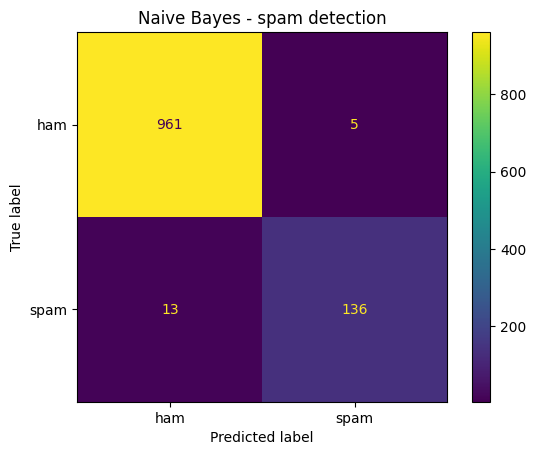

In [8]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
def evaluate(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred)}

nb_a = MultinomialNB()
nb_a.fit(Xtr_a, ytr_a)
pred_a = nb_a.predict(Xte_a)

nb_a_metrics = evaluate(yte_a, pred_a)
print(pd.Series(nb_a_metrics).round(4))

cm = confusion_matrix(yte_a, pred_a)
print("[[TN, FP], [FN, TP]] =", cm.tolist())
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot()
plt.title("Naive Bayes - spam detection"); plt.show()

**Task 5 — Spam Model Metrics**

⚠ *Fill in from the cell above.*

| Metric | Value |
|---|---|
| Accuracy | |
| Precision | |
| Recall | |
| F1-score | |

**Observation (confusion matrix):** ⚠ *Of the [__] spam messages in the test set, the model caught [TP] and let [FN] through; it wrongly flagged [FP] real messages as spam.*

**Answer 6:**
For spam filtering a false positive is the worse mistake. If a real (ham) message is flagged as spam, the user may never see something important, such as a bank code, a delivery notice or a message from a friend, and may not even know it was lost. A false negative only means one annoying spam message reaches the inbox, which the user can simply delete. Because we want to avoid flagging real messages, **precision** (of everything marked spam, how much really is spam) is the metric I would prioritise if I tuned the model further, while still keeping recall reasonable so most spam is caught.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [9]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
words = vec_a.get_feature_names_out()
diff = nb_a.feature_log_prob_[1] - nb_a.feature_log_prob_[0]     # log P(w|spam) - log P(w|ham)

top_spam = words[np.argsort(diff)[::-1][:15]]
top_ham = words[np.argsort(diff)[:15]]
print("Top 15 SPAM words:", list(top_spam))
print("\nTop 15 HAM words: ", list(top_ham))

Top 15 SPAM words: ['claim', 'prize', '150p', 'tone', '18', 'cs', '500', 'guaranteed', '1000', 'uk', '150ppm', 'awarded', 'www', 'collection', 'ringtone']

Top 15 HAM words:  ['gt', 'lt', 'he', 'da', 'lor', 'she', 'later', 'll', 'doing', 'say', 'ask', 'really', 'home', 'anything', 'amp']


**Answer 7:**
⚠ *Replace the brackets using the lists printed above.*

The top spam words are [list a few, e.g. words like "free", "claim", "prize", "txt", "call", "mobile", "reply", "www"], which match my intuition: spam is full of offers, urgency and calls to action such as calling a number or texting a short code. The top ham words are [list a few, e.g. everyday words like "ok", "lt", "gt", "my", "me", "home", "later"], which look like casual, conversational talk between people. Something that surprised me / did not match intuition: [e.g. a few rare or odd tokens, because words that appear only in spam get a very high ratio even though they are rare].

In [10]:
# Task 8 — test your own messages
my_messages = [
    "WINNER!! You have won a free prize. Call now to claim your 1000 cash reward",   # spam-like
    "Hey, are we still meeting for lunch tomorrow? Let me know what time works",    # normal
    "Urgent! Your account is blocked, click the link to verify and get a free gift",  # spam-like
]
vec_in = vec_a.transform([clean_sms(m) for m in my_messages])
probs = nb_a.predict_proba(vec_in)[:, 1]
for m, p in zip(my_messages, probs):
    print(f"{'SPAM' if p > 0.5 else 'HAM ':4} (P(spam) = {p:.3f})  <-  {m}")

SPAM (P(spam) = 1.000)  <-  WINNER!! You have won a free prize. Call now to claim your 1000 cash reward
HAM  (P(spam) = 0.000)  <-  Hey, are we still meeting for lunch tomorrow? Let me know what time works
SPAM (P(spam) = 1.000)  <-  Urgent! Your account is blocked, click the link to verify and get a free gift


**Answer 8:**
⚠ *Edit to match your own printed predictions.*

The obviously spam-like messages (free prize / urgent account / click the link) were predicted as [SPAM] and the casual lunch message as [HAM], which matches what I expected. [If one prediction was wrong, explain: Naive Bayes only counts words and treats them as independent, so a normal message that happens to contain words like "free" or "call" can be pushed toward spam, and a spam message written without typical spam words can slip through.]

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
⚠ *Paste your published notebook link here (https://www.kaggle.com/code/...). It must be PUBLIC.*

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [11]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
import re
def clean_tweet(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)      # remove links
    t = re.sub(r"@\w+", " ", t)                    # remove @mentions (airline handles)
    t = t.replace("#", " ")                          # keep the hashtag word, drop the symbol
    t = re.sub(r"[^a-z\s]", " ", t)                # keep letters only
    return re.sub(r"\s+", " ", t).strip()

tweets["clean"] = tweets["text"].apply(clean_tweet)
display(tweets[["text", "clean"]].head())

y_b = (tweets["airline_sentiment"] == "positive").astype(int)   # positive = 1, negative = 0
Xtr_b_txt, Xte_b_txt, ytr_b, yte_b = train_test_split(
    tweets["clean"], y_b, test_size=0.2, random_state=42, stratify=y_b)

vec_b = CountVectorizer(min_df=2)             # ignore words seen in only 1 tweet (typos/noise)
Xtr_b = vec_b.fit_transform(Xtr_b_txt)        # fit on TRAIN only
Xte_b = vec_b.transform(Xte_b_txt)
print("Train:", Xtr_b.shape, "| Test:", Xte_b.shape, "| Vocabulary:", len(vec_b.get_feature_names_out()))

,text,clean
1,@VirginAmerica plus you've added commercials t...,plus you ve added commercials to the experienc...
3,@VirginAmerica it's really aggressive to blast...,it s really aggressive to blast obnoxious ente...
4,@VirginAmerica and it's a really big bad thing...,and it s a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay a flight for seats that di...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm w...


Train: (9232, 4387) | Test: (2309, 4387) | Vocabulary: 4387


**Answer 12:**
Tweets are messier than SMS messages, so I did more cleaning: I removed links and @mentions (the airline handle, such as the airline's own name, appears in almost every tweet whatever the sentiment, so it adds noise rather than signal), turned hashtags into plain words, and kept letters only. I also used `min_df=2` so that typos and words seen in just one tweet do not bloat the vocabulary, and I kept the same fit-on-train-only discipline as Task A.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy     0.9155
Precision    0.8441
Recall       0.7209
F1           0.7777
dtype: float64
[[TN, FP], [FN, TP]] = [[1773, 63], [132, 341]]


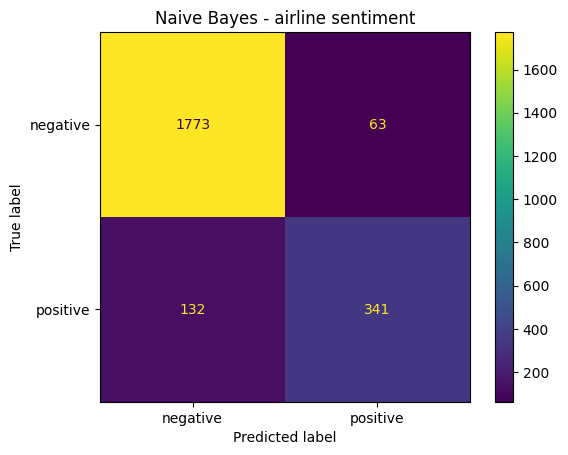

In [12]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
nb_b = MultinomialNB()
nb_b.fit(Xtr_b, ytr_b)
pred_b = nb_b.predict(Xte_b)

nb_b_metrics = evaluate(yte_b, pred_b)         # "positive" tweets are class 1
print(pd.Series(nb_b_metrics).round(4))

cm = confusion_matrix(yte_b, pred_b)
print("[[TN, FP], [FN, TP]] =", cm.tolist())
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot()
plt.title("Naive Bayes - airline sentiment"); plt.show()

**Task 13 — Sentiment Model Metrics**

⚠ *Fill in from the cell above. Class 1 = positive tweets.*

| Metric | Value |
|---|---|
| Accuracy | |
| Precision | |
| Recall | |
| F1-score | |

**Answer 14:**
⚠ *Check these claims against your two sets of metrics and edit them so they match your results (the usual pattern is that Naive Bayes does clearly worse on sentiment than on spam, especially on precision, recall and F1 for the minority class).*

Naive Bayes did [worse] on sentiment than on spam: accuracy was [__] vs [__], and F1 was [__] vs [__]. The "naive" assumption is that every word is independent given the class. That is fairly reasonable for short, formulaic spam, where certain words ("free", "claim", "prize") strongly signal the class regardless of the words around them. It is much less reasonable for tweets, where meaning depends on word order and context: negation ("not good", "never again") flips a word's sentiment, and sarcasm ("great, another delayed flight") uses positive words for a negative message. A bag-of-words model that scores each word on its own cannot capture these interactions, which hurts performance.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
⚠ *Paste your published notebook link here (https://www.kaggle.com/code/...). It must be PUBLIC.*

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

⚠ *Copy the first table printed by the Task 17/18 code cell.*

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | | |
| Precision | | |
| Recall | | |
| F1-score | | |

In [13]:
# Task 17 — Task A vs Task B (Naive Bayes)
nb_compare = pd.DataFrame({"Task A (Spam)": nb_a_metrics, "Task B (Sentiment)": nb_b_metrics}).round(4)
display(nb_compare)

# Task 18 — train Logistic Regression on Task A's vectorized features
lr_a = LogisticRegression(max_iter=1000, random_state=42)
lr_a.fit(Xtr_a, ytr_a)
lr_a_metrics = evaluate(yte_a, lr_a.predict(Xte_a))

nb_vs_lr = pd.DataFrame({"Naive Bayes": nb_a_metrics, "Logistic Regression": lr_a_metrics}).round(4)
display(nb_vs_lr)

,Task A (Spam),Task B (Sentiment)
Accuracy,0.9839,0.9155
Precision,0.9645,0.8441
Recall,0.9128,0.7209
F1,0.9379,0.7777


,Naive Bayes,Logistic Regression
Accuracy,0.9839,0.9812
Precision,0.9645,0.9923
Recall,0.9128,0.8658
F1,0.9379,0.9247


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

⚠ *Copy the second table printed by the Task 17/18 code cell.*

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | | |
| Precision | | |
| Recall | | |
| F1-score | | |

**Answer 18 (which wins, and does it match expectations):**
⚠ *Decide the winner from YOUR table, then adapt.*

[Model] wins on [F1 / precision / recall], although the difference is [small / large]. [Logistic Regression] is often slightly better or similar on text because it learns a weight for each word jointly, so it can account for words that carry overlapping information, while Naive Bayes assumes every word is independent. On the other hand, Naive Bayes is simpler, trains almost instantly and works very well on short, formulaic text like SMS spam, so it is not surprising that the two are close. This [does / does not] match my expectation.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
⚠ *Write 6–8 sentences with your numbers. Cover all four points below.*

Naive Bayes suited the spam task better, with an F1 of [__] versus [__] on sentiment, because spam messages use a small set of strongly indicative words and the independence assumption holds reasonably well, whereas tweets depend on context, negation and sarcasm. What surprised me about the most predictive words was [__]. Compared with Logistic Regression on the same features, Naive Bayes was [slightly worse / similar / better] ([metrics]), while being much simpler and faster. One limitation of the independence assumption that I observed is [e.g. a negated or sarcastic tweet, or a normal message containing spam-like words, being misclassified because each word was scored on its own]. Compared with the tabular classifiers from Labs 3–6, text needs vectorization and produces thousands of sparse features, but the same evaluation habits (precision, recall, F1 and the confusion matrix) still apply.

**Answer 20 — Kaggle Notebook Links:**
- Task A: ⚠ _paste link_
- Task B: ⚠ _paste link_

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted